<div class="dark-title" style="background:linear-gradient(90deg,#1e3a8a,#5b21b6); color:#f1f5f9; padding:20px 32px; border-radius:8px; width:97%;"><style>.dark-title strong{color:#fde047;}</style>

## 📡 Streaming 全表：graph 级 · token 级 · 自定义 · SDK

**一句话定位**：`stream_mode` 决定"每个 chunk 是什么"；本地 `graph.stream` 与远程 `client.runs.stream` 同一套概念。
> 本机 langgraph 1.2 实测；课件里"`messages` 模式只有 API 才支持"已过时。

</div>

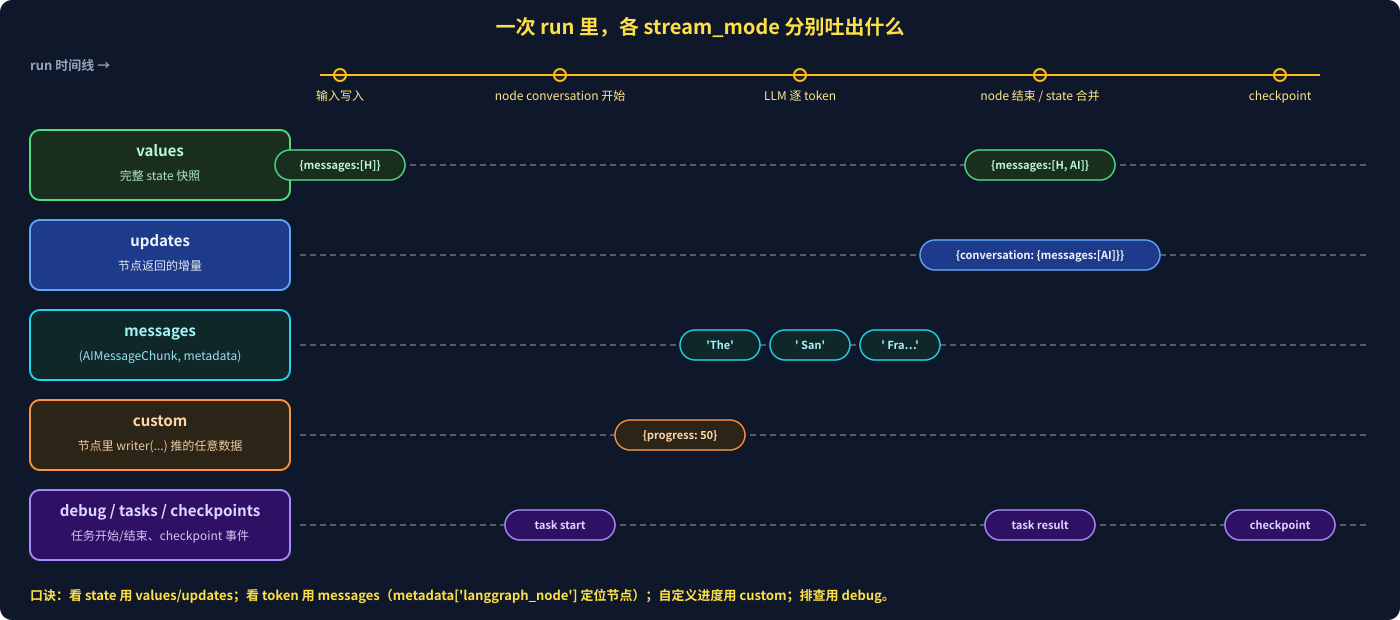

In [ ]:
from IPython.display import SVG
SVG(filename="assets/08_stream_modes.svg")

### 1️⃣ 模式总表（`graph.stream(input, config, stream_mode=...)`）

| 模式 | 每个 chunk | 典型用途 |
|---|---|---|
| `"values"` | 每步之后的**完整 state** | 看 state 演变；注意会"重复打印"旧消息 |
| `"updates"` | `{节点名: 该节点返回的增量}` | 调试单个节点；默认模式 |
| `"messages"` | `(AIMessageChunk, metadata)` | **逐 token** 输出；`metadata["langgraph_node"]` 过滤节点 |
| `"custom"` | 节点内 `get_stream_writer()(obj)` 推的任意对象 | 进度条、工具中间结果 |
| `"debug"` | tasks + checkpoints 事件 | 排查执行顺序 |
| `["updates","messages"]` | `(mode, chunk)` 元组 | 同时要状态和 token |
| `subgraphs=True` | `(namespace, chunk)`；子图事件带路径 | 看嵌套 agent 内部 |

In [ ]:
# 前置：本节代码共用的最小 graph（需要 OPENAI_API_KEY）
from langchain.chat_models import init_chat_model
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.graph import StateGraph, MessagesState, START, END

model = init_chat_model("openai:gpt-4o")

def conversation(state: MessagesState):
    return {"messages": [model.invoke(state["messages"])]}

graph = (StateGraph(MessagesState)
         .add_node("conversation", conversation)
         .add_edge(START, "conversation")
         .add_edge("conversation", END)
         .compile(checkpointer=InMemorySaver()))
config = {"configurable": {"thread_id": "1"}}
inputs = {"messages": [("human", "hi")]}

In [ ]:
# ① graph 级
for chunk in graph.stream({"messages": [("human", "hi")]}, config, stream_mode="updates"):
    print(chunk)                                  # {'conversation': {'messages': [AIMessage(...)]}}

for state in graph.stream(inputs, config, stream_mode="values"):
    state["messages"][-1].pretty_print()          # 每步打印最新一条即可，避免重复

# ② token 级（本地可用，比 astream_events 简单）
for chunk, metadata in graph.stream(inputs, config, stream_mode="messages"):
    if metadata["langgraph_node"] == "conversation":
        print(chunk.content, end="|", flush=True)

# ③ 自定义
from langgraph.config import get_stream_writer
def my_node(state):
    writer = get_stream_writer()
    writer({"progress": 50})                      # stream_mode="custom" 能收到
    return {"x": 1}

# ④ 多模式 + 子图
for mode, chunk in graph.stream(inputs, config, stream_mode=["updates", "messages"], subgraphs=True):
    ...

<div class="dark-warning" style="background:#2a2418; color:#fde68a; padding:12px 24px; border-left:4px solid #fbbf24; border-radius:4px; width:97%;"><style>.dark-warning strong{color:#f9a8d4;}</style>

**三个坑**
1. `values` 每步都是**全量**，循环里只打印 `[-1]`。
2. 节点里 `model.invoke()` 的 token 要能流出来，模型本身需支持 streaming（LangChain chat model 默认支持）；Python < 3.11 的 **async** 节点要把 `config` 显式传给 `model.ainvoke(messages, config)`。
3. `get_stream_writer()` 在 Python < 3.11 的 async 里不工作 → 改用节点参数 `writer: StreamWriter`。

</div>

### 2️⃣ 事件流：`astream_events`（旧，仍可用）vs `stream_events`（🆕 1.2 beta）

In [ ]:
# 旧：LangChain 通用事件流，信息最全但最啰嗦（每个 token 一个 on_chat_model_stream）
async for ev in graph.astream_events(inputs, config, version="v2"):
    if ev["event"] == "on_chat_model_stream" and ev["metadata"].get("langgraph_node") == "conversation":
        print(ev["data"]["chunk"].content, end="|")

# 新：类型化事件（1.2 起，API 可能变）
for ev in graph.stream_events(inputs, config, version="v3"):
    ...

### 3️⃣ 远程（LangGraph SDK）对照

| 本地 | SDK（`client.runs.stream(thread_id, assistant_id, input=..., stream_mode=...)`） |
|---|---|
| `stream_mode="values"` | `"values"` → `chunk.event == "values"`, `chunk.data` = state |
| `"updates"` | `"updates"` |
| `"messages"` | `"messages-tuple"` → `chunk.event == "messages"`, `chunk.data` = `[token_dict, metadata]` |
| — | `"messages"`（旧事件风格）→ `messages/metadata` · `messages/partial` · `messages/complete` |
| `astream_events` | `"events"` |
| 多模式 | `stream_mode=["values", "messages-tuple"]` |

```python
async for chunk in client.runs.stream(thread["thread_id"], "agent", input=inputs, stream_mode="messages-tuple"):
    if chunk.event == "messages":
        print("".join(d["content"] for d in chunk.data if "content" in d), end="")
```
返回的消息是 **dict**，要变回对象用 `convert_to_messages(chunk.data["messages"])`。

### 🧭 选哪种

| 需求 | 用 |
|---|---|
| 聊天 UI 打字机效果 | `messages`（SDK：`messages-tuple`） |
| 看每个节点做了什么 | `updates` |
| 断点 / HITL 后看当前 state | `values`（只看 `[-1]`） |
| 工具长任务进度 | `custom` + `get_stream_writer` |
| 多 agent 嵌套 | `subgraphs=True` |
| 排查顺序 / 并行 | `debug` 或 LangSmith trace |

<div class="dark-success" style="background:#1a2e1f; color:#bbf7d0; padding:10px 24px; border-left:4px solid #4ade80; border-radius:4px; width:97%;"><style>.dark-success strong{color:#fbbf24;}</style>

**✨ 一句话带走**：`stream_mode` 四选一（values / updates / messages / custom），可组合；**token 流就是 `messages` 模式 + `metadata["langgraph_node"]` 过滤**，本地远程一致；`astream_events` 只在要看 LangChain 内部所有事件时才用。

</div>